# 01 — Premiers pas : un modèle de diffusion « jouet » en 2D

**Projet HMM (ENSAE) — papier étudié :** Janati, Moufad, Durmus, Moulines, Olsson (2024),
*Divide-and-Conquer Posterior Sampling for Denoising Diffusion Priors*, NeurIPS.

## Pourquoi commencer en 2D ?

Le papier traite des images (des centaines de milliers de dimensions). Avant ça, il fait lui-même
une expérience jouet (Section 4, « Gaussian mixture », et Annexe C.2) : le prior est un
**mélange de 25 gaussiennes**. On reprend cette expérience, en dimension $d=2$, parce que :

1. **pas besoin de réseau de neurones** : pour un mélange gaussien, le « débruiteur » que le réseau
   apprend normalement se calcule à la main ;
2. **le vrai posterior est connu exactement** : on peut donc *mesurer* l'erreur des méthodes ;
3. **tout se dessine** : on voit ce que fait chaque algorithme.

## Plan du notebook

1. Le prior : un mélange de 25 gaussiennes
2. Le bruitage (processus *forward*)
3. Le débruitage (processus *backward*, DDPM) : une chaîne de Markov
4. Le problème inverse et son vrai posterior
5. Une première méthode Monte Carlo : l'échantillonnage préférentiel
6. Bilan et suite

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp

rng = np.random.default_rng(seed=0)   # graine fixée : les résultats sont reproductibles

# Couleurs utilisées dans tout le notebook
GRIS = "#9a9a96"     # prior (sert de contexte)
BLEU = "#2a78d6"     # posterior / estimations
ORANGE = "#eb6834"   # la vérité (x*, vraie valeur)
AQUA = "#1baf7a"     # troisième série si besoin
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

## 1. Le prior : un mélange de 25 gaussiennes

On note $p_{\text{data}}$ la loi des « données » (ici des points de $\mathbb{R}^2$ ; plus tard, des images) :

$$
p_{\text{data}}(x) \;=\; \sum_{i=1}^{25} w_i \, \mathcal{N}(x;\, m_i,\, I_2),
\qquad m_i \in \{(8a, 8b) : a, b \in \{-2,-1,0,1,2\}\}.
$$

- les 25 moyennes $m_i$ forment une grille de pas 8 (comme dans l'Annexe C.2 du papier) ;
- chaque composante a une covariance identité ;
- les poids $w_i$ sont tirés au hasard selon une loi de Dirichlet(1, …, 1), donc certains « blobs »
  contiennent beaucoup plus de points que d'autres.

**Simuler** selon $p_{\text{data}}$ se fait en deux temps : on choisit une composante $i$ avec
probabilité $w_i$, puis on tire $x = m_i + \varepsilon$ avec $\varepsilon \sim \mathcal{N}(0, I_2)$.

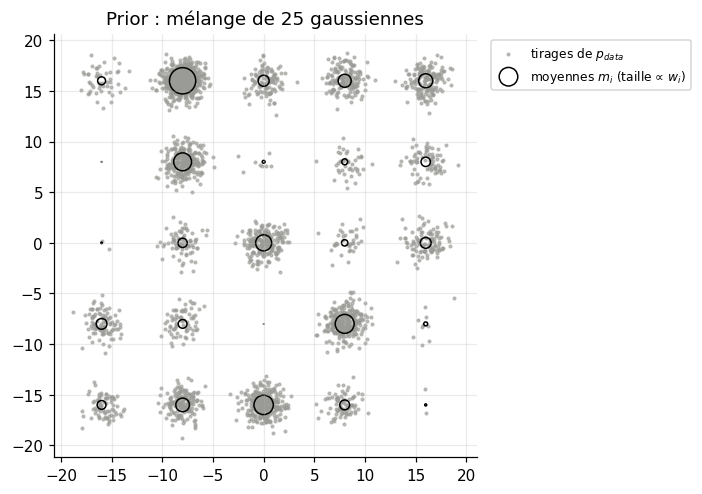

plus grand poids : 0.197 | plus petit poids : 4.2e-05


In [2]:
d = 2                                      # dimension de x
grille = np.array([-2, -1, 0, 1, 2])
means = 8.0 * np.array([(a, b) for a in grille for b in grille])   # tableau (25, 2) : les moyennes m_i
K = len(means)                             # nombre de composantes (25)
weights = rng.dirichlet(np.ones(K))        # poids w_i (positifs, somme = 1)

def sample_prior(N):
    # Tire N points selon p_data. Renvoie un tableau (N, 2).
    comp = rng.choice(K, size=N, p=weights)              # 1) composante i avec probabilité w_i
    return means[comp] + rng.standard_normal((N, d))     # 2) x = m_i + bruit N(0, I)

x_prior = sample_prior(3000)

fig, ax = plt.subplots(figsize=(7.2, 5))
ax.scatter(*x_prior.T, s=3, color=GRIS, alpha=0.6, label="tirages de $p_{data}$")
ax.scatter(*means.T, s=1500 * weights, facecolor="none", edgecolor="black", lw=1,
           label="moyennes $m_i$ (taille ∝ $w_i$)")
ax.set_aspect("equal"); ax.set_title("Prior : mélange de 25 gaussiennes")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
plt.show()
print(f"plus grand poids : {weights.max():.3f} | plus petit poids : {weights.min():.1e}")

## 2. Le bruitage (processus *forward*)

Un modèle de diffusion part d'une donnée $X_0 \sim p_{\text{data}}$ et lui ajoute du bruit,
petit à petit, pendant $n$ étapes, jusqu'à obtenir du bruit pur. On se donne une suite
$1 = \alpha_0 > \alpha_1 > \dots > \alpha_n \approx 0$ (notation du papier, Section 2), et

$$
X_{k+1} \;=\; \sqrt{\alpha_{k+1}/\alpha_k}\; X_k \;+\; \sqrt{1-\alpha_{k+1}/\alpha_k}\;\varepsilon_{k+1},
\qquad \varepsilon_{k+1} \sim \mathcal{N}(0, I) \text{ i.i.d.}
$$

**C'est une chaîne de Markov** (un AR(1) dont les coefficients changent avec $k$). En combinant
les étapes, on obtient directement la loi de $X_k$ sachant $X_0$ :

$$
X_k \;=\; \sqrt{\alpha_k}\, X_0 + \sqrt{1-\alpha_k}\;\varepsilon,
\qquad\text{c'est-à-dire}\qquad
q_{k|0}(x_k \mid x_0) = \mathcal{N}\big(x_k;\ \sqrt{\alpha_k}\,x_0,\ (1-\alpha_k) I\big).
$$

- quand $k$ est petit, $\alpha_k \approx 1$ : $X_k \approx X_0$ (presque pas de bruit) ;
- quand $k = n$, $\alpha_n \approx 0$ : $X_n \approx \mathcal{N}(0, I)$, on a oublié $X_0$.

On prend le choix classique de DDPM (Ho et al., 2020) : $n = 1000$ et
$\alpha_k = \prod_{t=1}^{k} (1-\beta_t)$ avec $\beta_t$ allant linéairement de $10^{-4}$ à $0{,}02$.

alpha_0 = 1.0,  alpha_n = 4.0e-05


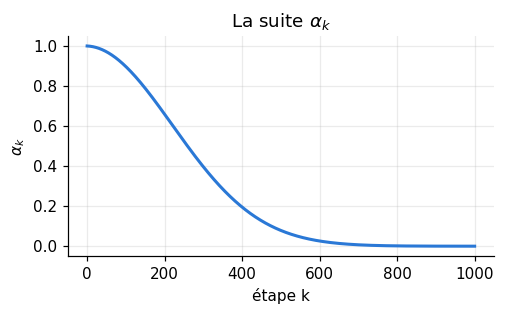

In [3]:
n = 1000
betas = np.linspace(1e-4, 0.02, n)
alphas = np.concatenate([[1.0], np.cumprod(1 - betas)])   # alphas[k] pour k = 0, ..., n
print(f"alpha_0 = {alphas[0]},  alpha_n = {alphas[n]:.1e}")

def forward_sample(x0, k):
    # Tire X_k sachant X_0 = x0, directement : X_k = sqrt(alpha_k) x0 + sqrt(1 - alpha_k) eps
    eps = rng.standard_normal(x0.shape)
    return np.sqrt(alphas[k]) * x0 + np.sqrt(1 - alphas[k]) * eps

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(np.arange(n + 1), alphas, color=BLEU, lw=2)
ax.set_xlabel("étape k"); ax.set_ylabel(r"$\alpha_k$"); ax.set_title(r"La suite $\alpha_k$")
plt.show()

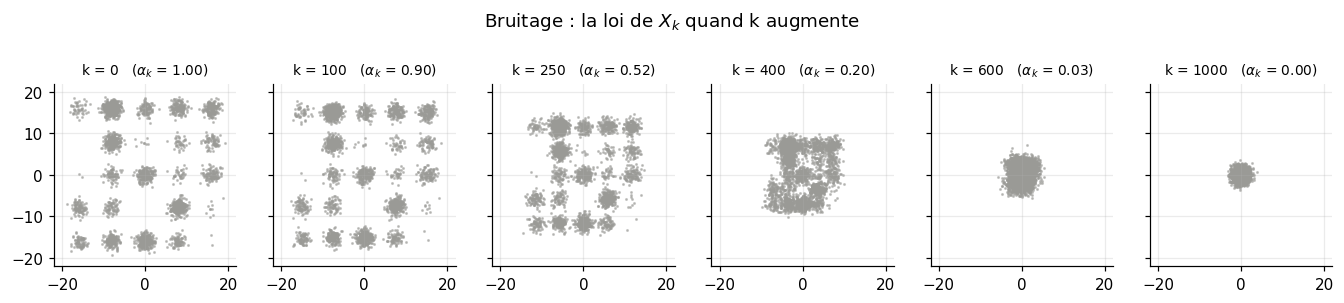

In [4]:
etapes = [0, 100, 250, 400, 600, 1000]
fig, axes = plt.subplots(1, len(etapes), figsize=(15, 2.8), sharex=True, sharey=True)
for ax, k in zip(axes, etapes):
    xk = forward_sample(x_prior, k)
    ax.scatter(*xk.T, s=1, color=GRIS, alpha=0.5)
    ax.set_title(f"k = {k}   ($\\alpha_k$ = {alphas[k]:.2f})", fontsize=9)
    ax.set_xlim(-22, 22); ax.set_ylim(-22, 22); ax.set_aspect("equal")
fig.suptitle("Bruitage : la loi de $X_k$ quand k augmente", y=1.03)
plt.show()

Le nuage se « contracte » (facteur $\sqrt{\alpha_k}$) et se « floute » (bruit de variance $1-\alpha_k$),
jusqu'à devenir une gaussienne standard à $k = n$.

## 3. Le débruitage (processus *backward*, DDPM)

Pour **générer** de nouvelles données, on remonte le temps : on part de $X_n \sim \mathcal{N}(0, I)$ et on
tire successivement $X_{n-1}, X_{n-2}, \dots, X_0$. Il faudrait connaître la vraie loi de $X_k$
sachant $X_{k+1}$, qui n'est pas calculable. DDPM l'approche en deux temps (équations (2.1)–(2.2) du papier) :

1. **Deviner $X_0$** à partir de $x_{k+1}$ avec le *débruiteur*
   $\hat x_{0|k+1}(x_{k+1}) \approx \mathbb{E}[X_0 \mid X_{k+1} = x_{k+1}]$.
   C'est **ce que le réseau de neurones apprend**. Plus tard, pour les images, on téléchargera un réseau déjà entraîné.
2. **Tirer $X_k$ dans le « pont » gaussien** : la loi de $X_k$ sachant les deux extrémités
   $X_0 = \hat x_0$ et $X_{k+1} = x_{k+1}$ est une gaussienne explicite (Annexe A.1, éq. (A.2)–(A.3)) :

$$
q_{j|0,k}(x_j \mid x_0, x_k) = \mathcal{N}\big(x_j;\ \mu_{j|0,k}(x_0,x_k),\ \sigma^2_{j|k} I\big),
\quad
\mu_{j|0,k} = \frac{\sqrt{\alpha_j}\,(1-\alpha_k/\alpha_j)}{1-\alpha_k}\,x_0 + \frac{\sqrt{\alpha_k/\alpha_j}\,(1-\alpha_j)}{1-\alpha_k}\,x_k,
\quad
\sigma^2_{j|k} = \frac{(1-\alpha_j)(1-\alpha_k/\alpha_j)}{1-\alpha_k}.
$$

La transition DDPM est donc $p_{k|k+1}(x_k \mid x_{k+1}) = q_{k|0,k+1}\big(x_k \mid \hat x_{0|k+1}(x_{k+1}),\, x_{k+1}\big)$.

### Le débruiteur exact pour notre mélange

Ici, pas besoin de réseau. Si $X_0$ vient de la composante $i$, alors $X_0 \sim \mathcal N(m_i, I)$ et
$X_k = \sqrt{\alpha_k} X_0 + \sqrt{1-\alpha_k}\,\varepsilon \sim \mathcal{N}(\sqrt{\alpha_k}\, m_i,\ I)$
(variance $\alpha_k + (1-\alpha_k) = 1$). Donc :

- **probabilité d'être dans la composante $i$** sachant $X_k = x$ (la « responsabilité ») :
  $\;r_i(x) \propto w_i\, \mathcal{N}(x;\, \sqrt{\alpha_k}\, m_i,\, I)$ ;
- **dans la composante $i$**, $(X_0, X_k)$ est un vecteur gaussien avec $\mathrm{Cov}(X_0, X_k) = \sqrt{\alpha_k}\, I$ et
  $\mathrm{Var}(X_k) = I$. Le conditionnement gaussien donne
  $\mathbb{E}[X_0 \mid X_k = x, i] = m_i + \sqrt{\alpha_k}\,(x - \sqrt{\alpha_k}\, m_i)$.

En moyennant sur $i$ avec les poids $r_i(x)$ :

$$
\boxed{\;\hat x_{0|k}(x) = \sqrt{\alpha_k}\; x \;+\; (1-\alpha_k) \sum_{i} r_i(x)\, m_i\;}
$$

Interprétation : pour $k$ petit (peu de bruit), $\hat x_{0|k}(x) \approx x$ ; pour $k$ grand (beaucoup
de bruit), $\hat x_{0|k}(x) \approx$ une moyenne pondérée des centres $m_i$.

In [5]:
def denoiser(x, k):
    # Débruiteur exact : x_hat_{0|k}(x) = E[X_0 | X_k = x].  x : tableau (N, 2) -> (N, 2)
    a = alphas[k]
    # log(w_i) + log N(x; sqrt(a) m_i, I), à une constante près -> tableau (N, K)
    sq_dist = ((x[:, None, :] - np.sqrt(a) * means[None, :, :]) ** 2).sum(axis=2)
    log_r = np.log(weights)[None, :] - 0.5 * sq_dist
    r = np.exp(log_r - logsumexp(log_r, axis=1, keepdims=True))   # responsabilités r_i(x) (somme 1 par ligne)
    return np.sqrt(a) * x + (1 - a) * r @ means

def bridge_mean_var(x0, xk, j, k):
    # Loi de X_j sachant X_0 = x0 et X_k = xk (avec j < k) : N(mean, var * I). Éq. (A.2)-(A.3).
    aj, ak = alphas[j], alphas[k]
    mean = (np.sqrt(aj) * (1 - ak / aj) / (1 - ak)) * x0 + (np.sqrt(ak / aj) * (1 - aj) / (1 - ak)) * xk
    var = (1 - aj) * (1 - ak / aj) / (1 - ak)
    return mean, var

def ddpm_step(x_next, k):
    # Une transition backward p_{k|k+1} : on passe de X_{k+1} = x_next à X_k
    x0_hat = denoiser(x_next, k + 1)                     # 1) on devine X_0
    if k == 0:
        return x0_hat                                    # dernière étape : X_0 = x_hat_{0|1}(X_1)
    mean, var = bridge_mean_var(x0_hat, x_next, k, k + 1)  # 2) pont gaussien
    return mean + np.sqrt(var) * rng.standard_normal(x_next.shape)

def ddpm_sample(N, keep=()):
    # Simule N chaînes backward X_n -> X_{n-1} -> ... -> X_0. Garde une copie aux étapes de `keep`.
    x = rng.standard_normal((N, d))                      # X_n ~ N(0, I)
    saved = {n: x.copy()}
    for k in range(n - 1, -1, -1):
        x = ddpm_step(x, k)
        if k in keep:
            saved[k] = x.copy()
    return x, saved

t0 = time.time()
x_ddpm, saved = ddpm_sample(2000, keep=etapes)
print(f"2000 tirages DDPM en {time.time() - t0:.1f} s  ({n} appels au débruiteur)")

2000 tirages DDPM en 9.9 s  (1000 appels au débruiteur)


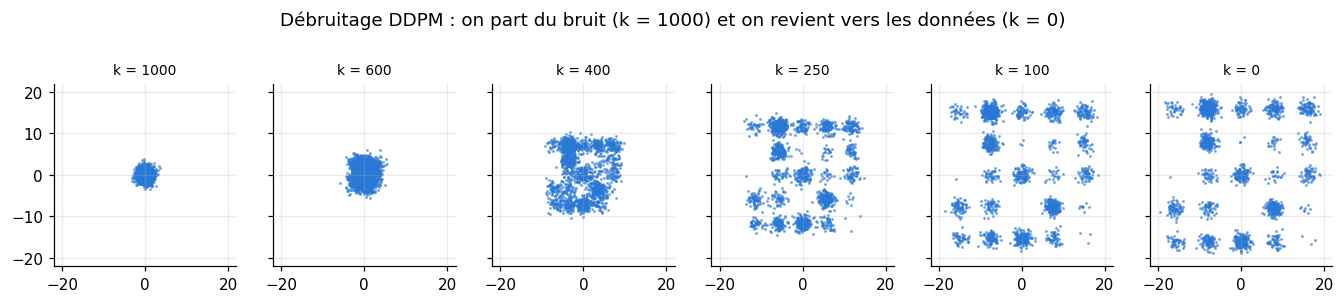

In [6]:
fig, axes = plt.subplots(1, len(etapes), figsize=(15, 2.8), sharex=True, sharey=True)
for ax, k in zip(axes, etapes[::-1]):
    ax.scatter(*saved[k].T, s=1, color=BLEU, alpha=0.5)
    ax.set_title(f"k = {k}", fontsize=9)
    ax.set_xlim(-22, 22); ax.set_ylim(-22, 22); ax.set_aspect("equal")
fig.suptitle("Débruitage DDPM : on part du bruit (k = 1000) et on revient vers les données (k = 0)", y=1.03)
plt.show()

**Vérification.** Si le DDPM est correct, la proportion de points tombés dans chaque composante doit être
proche du poids $w_i$. On attribue chaque point au centre $m_i$ le plus proche (les centres sont
séparés de 8 écarts-types, donc les erreurs d'attribution sont négligeables).

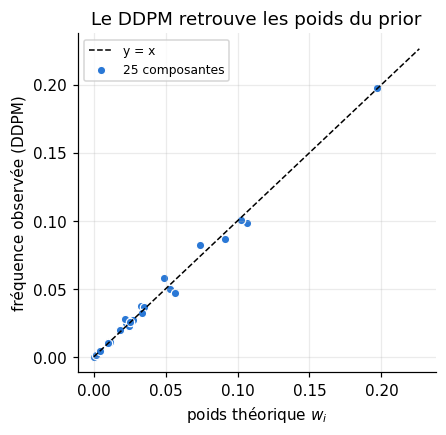

variance intra-composante (doit valoir ~1) : [1.   1.04]


In [7]:
def nearest_component(x):
    # Indice du centre m_i le plus proche de chaque point de x
    return ((x[:, None, :] - means[None, :, :]) ** 2).sum(axis=2).argmin(axis=1)

lab = nearest_component(x_ddpm)
freq = np.bincount(lab, minlength=K) / len(x_ddpm)   # proportion de points dans chaque composante
fig, ax = plt.subplots(figsize=(4.2, 4))
lim = weights.max() * 1.15
ax.plot([0, lim], [0, lim], color="black", lw=1, ls="--", label="y = x")
ax.scatter(weights, freq, s=30, color=BLEU, edgecolor="white", lw=0.8, label="25 composantes")
ax.set_xlabel("poids théorique $w_i$"); ax.set_ylabel("fréquence observée (DDPM)")
ax.set_title("Le DDPM retrouve les poids du prior"); ax.legend(fontsize=8)
plt.show()
print("variance intra-composante (doit valoir ~1) :", np.var(x_ddpm - means[lab], axis=0).round(2))

### Lien avec le cours (chaînes de Markov, modèles de Feynman–Kac)

Le modèle génératif est une **chaîne de Markov qui remonte le temps** (éq. (2.1) du papier) :

$$
p_{0:n}(x_{0:n}) = p_n(x_n) \prod_{k=0}^{n-1} p_{k|k+1}(x_k \mid x_{k+1}),
\qquad p_n = \mathcal{N}(0, I).
$$

Le **prior** utilisé dans le problème inverse est sa loi marginale en $k = 0$, notée $p_0$
(ici $p_0 \approx p_{\text{data}}$, on vient de le vérifier). Si on renomme le temps $t = n - k$, on
retrouve exactement le cadre du cours : loi initiale $M_0 = \mathcal{N}(0, I)$, noyaux de
transition $M_t = p_{k|k+1}$. C'est ce qui permettra d'utiliser des **filtres particulaires**.

## 4. Le problème inverse et son vrai posterior

On observe une version **dégradée et bruitée** d'un point inconnu $x^\star$ :

$$
y = A\,x^\star + \sigma_y\,\varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I_{d_y}).
$$

Comme dans le papier, on prend $d_y = 1$ : $A$ est une matrice $1 \times 2$, on n'observe qu'**une seule
combinaison linéaire** des deux coordonnées. Connaître $y$ dit seulement que $x^\star$ est
« près de la droite » $\{x : Ax = y\}$. Plusieurs blobs du prior coupent cette droite, donc le posterior
aura **plusieurs modes**.

- **Vraisemblance** : $g_0(x) = p(y \mid x) = \mathcal{N}(y;\, Ax,\, \sigma_y^2 I)$.
- **Posterior** (éq. (2.3)) : $\pi_0(x) = g_0(x)\, p_0(x) / Z$.

Pour un prior mélange gaussien et une vraisemblance linéaire gaussienne, le posterior est
**encore un mélange gaussien**, calculable exactement (Annexe C.2 du papier ; Bishop (2006), éq. 2.116).
Chaque composante est « mise à jour » comme en régression bayésienne :

$$
\pi_0(x) = \sum_i \tilde w_i\, \mathcal{N}(x;\, \tilde m_i,\, \Sigma), \qquad
\Sigma = \big(I + \sigma_y^{-2} A^\top A\big)^{-1}, \qquad
\tilde m_i = \Sigma\big(A^\top y / \sigma_y^2 + m_i\big),
$$
$$
\tilde w_i \propto w_i \, \mathcal{N}\big(y;\, A m_i,\, \sigma_y^2 I + A A^\top\big).
$$

Le nouveau poids $\tilde w_i$ = poids a priori × « à quel point la composante $i$ explique $y$ ».

In [8]:
# Le problème inverse (graine séparée pour qu'il ne dépende pas des tirages précédents)
rng_pb = np.random.default_rng(10)
d_y = 1
sigma_y = 1.0
A = rng_pb.standard_normal((d_y, d))                            # matrice d'observation (1 x 2)
comp_star = rng_pb.choice(K, p=weights)
x_star = means[comp_star] + rng_pb.standard_normal(d)           # la vraie valeur inconnue x*
y = A @ x_star + sigma_y * rng_pb.standard_normal(d_y)          # l'observation
print("A =", A.round(2), "| x* =", x_star.round(2), "| y =", y.round(2))

def exact_posterior(y, sigma_y):
    # Paramètres du posterior (mélange gaussien) : poids, moyennes (K, 2), covariance commune (2, 2)
    Sigma = np.linalg.inv(np.eye(d) + A.T @ A / sigma_y**2)
    post_means = (Sigma @ (A.T @ y[:, None] / sigma_y**2 + means.T)).T
    S = sigma_y**2 * np.eye(d_y) + A @ A.T                       # covariance de y sachant la composante i
    resid = y[None, :] - means @ A.T                             # y - A m_i, tableau (K, d_y)
    log_w = np.log(weights) - 0.5 * np.einsum("ki,ij,kj->k", resid, np.linalg.inv(S), resid)
    post_w = np.exp(log_w - logsumexp(log_w))
    return post_w, post_means, Sigma

def sample_posterior(N, y, sigma_y):
    post_w, post_means, Sigma = exact_posterior(y, sigma_y)
    comp = rng.choice(K, size=N, p=post_w)
    return post_means[comp] + rng.standard_normal((N, d)) @ np.linalg.cholesky(Sigma).T

post_w, post_means, Sigma = exact_posterior(y, sigma_y)
true_mean = post_w @ post_means                                  # vraie moyenne a posteriori E[X | y]
print("poids a posteriori les plus grands :", np.sort(post_w)[::-1][:4].round(3))
print("vraie moyenne a posteriori :", true_mean.round(3))

A = [[-1.1  -0.73]] | x* = [8.27 7.75] | y = [-14.61]
poids a posteriori les plus grands : [0.415 0.276 0.259 0.046]
vraie moyenne a posteriori : [8.287 7.473]


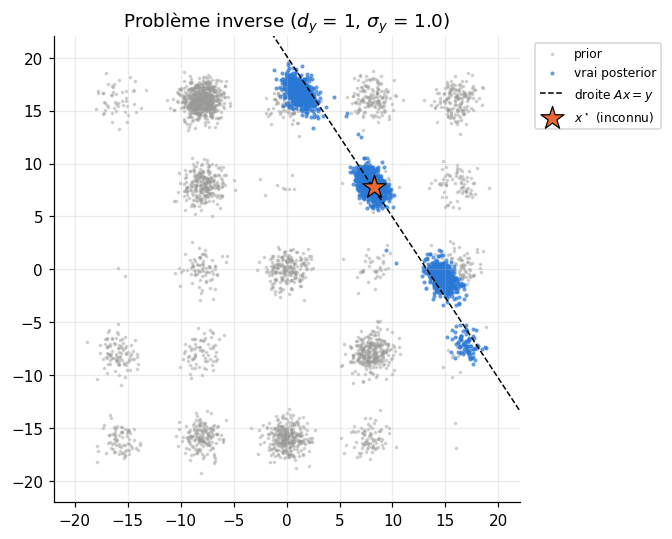

In [9]:
x_post = sample_posterior(2000, y, sigma_y)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(*x_prior.T, s=2, color=GRIS, alpha=0.35, label="prior")
ax.scatter(*x_post.T, s=3, color=BLEU, alpha=0.6, label="vrai posterior")
t = np.linspace(-22, 22, 2)                                     # droite {x : A x = y}
ax.plot(t, (y[0] - A[0, 0] * t) / A[0, 1], color="black", lw=1, ls="--", label="droite $Ax = y$")
ax.scatter(*x_star, marker="*", s=250, color=ORANGE, edgecolor="black", lw=0.8, zorder=5, label="$x^\\star$ (inconnu)")
ax.set_xlim(-22, 22); ax.set_ylim(-22, 22); ax.set_aspect("equal")
ax.set_title(f"Problème inverse ($d_y$ = 1, $\\sigma_y$ = {sigma_y})")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
plt.show()

Le posterior (en bleu) est concentré près de la droite $Ax = y$, mais **uniquement là où le prior a de
la masse** : il garde trois modes principaux. Un bon algorithme doit retrouver **tous** ces modes, avec
les bonnes proportions, et pas seulement « une image plausible ». C'est ce qu'on pourra vérifier ici,
et plus du tout avec des images.

## 5. Une première méthode Monte Carlo : l'échantillonnage préférentiel

La méthode la plus simple : on sait **simuler selon le prior** (avec le DDPM), donc on fait de
l'**échantillonnage préférentiel** (importance sampling, IS) avec le prior comme loi de proposition :

1. tirer $X^1, \dots, X^N \sim p_0$ ;
2. pondérer : $W^j = g_0(X^j) / \sum_l g_0(X^l)$ ;
3. estimer $\mathbb{E}_{\pi_0}[\varphi(X)] \approx \sum_j W^j \varphi(X^j)$.

C'est l'estimateur auto-normalisé du cours : il est convergent quand $N \to \infty$. Pour juger la qualité
des poids, on regarde la **taille d'échantillon effective** $\mathrm{ESS} = 1 / \sum_j (W^j)^2$, comprise
entre 1 (un seul point porte tout le poids) et $N$ (poids tous égaux).

> **Lien avec le cours.** C'est exactement un **filtre particulaire bootstrap** sur la chaîne backward
> du §3, avec des potentiels $G_t = 1$ à toutes les étapes sauf la dernière, où $G = g_0$ : toute
> l'information de $y$ arrive d'un coup, à la fin. On n'a donc jamais besoin de rééchantillonner avant la fin.

ESS = 42 sur N = 2000  (2 %)
estimation IS de E[X|y] : [7.534 8.477] | vraie valeur : [8.287 7.473]


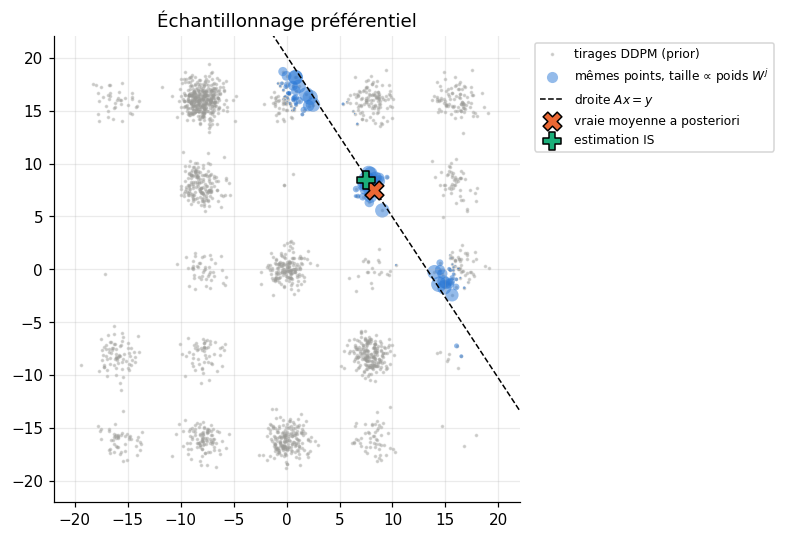

In [10]:
def importance_sampling(N, y, sigma_y, x=None):
    # IS avec le prior comme proposition. Renvoie (estimation de E[X|y], ESS, points, poids)
    if x is None:
        x = sample_prior(N)          # tirage exact du prior (plus rapide que le DDPM, même loi ici)
    log_g = -0.5 * ((y[None, :] - x @ A.T) ** 2).sum(axis=1) / sigma_y**2   # log g_0(x) + constante
    W = np.exp(log_g - logsumexp(log_g))                                      # poids normalisés
    return W @ x, 1.0 / np.sum(W**2), x, W

# Avec les 2000 tirages DDPM du §3 :
est, ess, x_is, W = importance_sampling(len(x_ddpm), y, sigma_y, x=x_ddpm)
print(f"ESS = {ess:.0f} sur N = {len(x_ddpm)}  ({100 * ess / len(x_ddpm):.0f} %)")
print("estimation IS de E[X|y] :", est.round(3), "| vraie valeur :", true_mean.round(3))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(*x_is.T, s=2, color=GRIS, alpha=0.35, label="tirages DDPM (prior)")
visible = W > 1e-4                                   # les autres points ont un poids quasi nul
ax.scatter(*x_is[visible].T, s=3000 * W[visible], color=BLEU, alpha=0.5, lw=0,
           label="mêmes points, taille ∝ poids $W^j$")
ax.plot(t, (y[0] - A[0, 0] * t) / A[0, 1], color="black", lw=1, ls="--", label="droite $Ax = y$")
ax.scatter(*true_mean, marker="X", s=150, color=ORANGE, edgecolor="black", zorder=5, label="vraie moyenne a posteriori")
ax.scatter(*est, marker="P", s=150, color=AQUA, edgecolor="black", zorder=6, label="estimation IS")
ax.set_xlim(-22, 22); ax.set_ylim(-22, 22); ax.set_aspect("equal")
ax.set_title("Échantillonnage préférentiel"); ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
plt.show()

### Variabilité Monte Carlo : on répète l'expérience

Un résultat Monte Carlo est **aléatoire** : une seule exécution ne suffit pas. On répète l'IS
**10 fois** pour chaque taille $N$ et on trace la distribution de l'erreur
$\lVert \hat\mu_N - \mathbb{E}[X \mid y] \rVert$ (boîtes à moustaches, un point par répétition).
On s'attend à une erreur qui décroît en $1/\sqrt{N}$.

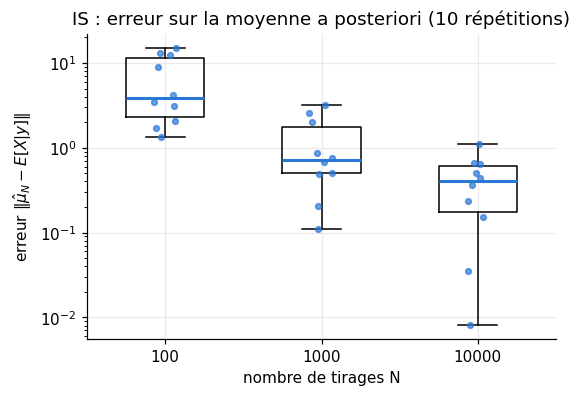

N =    100 : erreur médiane = 3.815
N =   1000 : erreur médiane = 0.721
N =  10000 : erreur médiane = 0.401


In [11]:
R = 10                                  # nombre de répétitions indépendantes
N_list = [100, 1_000, 10_000]
errors = {N: [np.linalg.norm(importance_sampling(N, y, sigma_y)[0] - true_mean) for _ in range(R)]
          for N in N_list}

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.boxplot([errors[N] for N in N_list], tick_labels=[str(N) for N in N_list], widths=0.5,
           medianprops=dict(color=BLEU, lw=2))
for pos, N in enumerate(N_list, start=1):
    ax.scatter(pos + rng.uniform(-0.08, 0.08, R), errors[N], s=14, color=BLEU, alpha=0.7, zorder=3)
ax.set_yscale("log"); ax.set_xlabel("nombre de tirages N")
ax.set_ylabel(r"erreur $\|\hat\mu_N - E[X|y]\|$")
ax.set_title(f"IS : erreur sur la moyenne a posteriori ({R} répétitions)")
plt.show()
for N in N_list:
    print(f"N = {N:>6} : erreur médiane = {np.median(errors[N]):.3f}")

**Lecture.** L'erreur diminue bien quand $N$ augmente, mais deux choses sautent aux yeux :
- pour $N = 100$, l'erreur est énorme (plusieurs unités) : avec si peu de tirages, très peu tombent près de
  la droite, et l'estimation « saute » d'un mode à l'autre ;
- d'une répétition à l'autre, l'erreur varie d'un facteur 10 environ. Avec seulement 10 répétitions, la médiane
  elle-même est imprécise : c'est pour ça qu'on montre **toute la distribution** et pas un seul chiffre.

En théorie, l'erreur de l'IS décroît en $1/\sqrt{N}$ (division par $\sqrt{10} \approx 3{,}2$ quand $N$ est multiplié par 10).
Comparez avec les médianes affichées ci-dessus : avec 10 répétitions seulement, il faut s'attendre à des écarts
à cette règle.

### Le problème : les poids dégénèrent quand l'observation est précise

Que se passe-t-il quand le bruit d'observation $\sigma_y$ diminue ? La vraisemblance devient
très « piquée » autour de la droite $Ax = y$ : seuls quelques tirages du prior tombent assez près,
et ils emportent presque tout le poids. On trace l'ESS relatif ($\mathrm{ESS}/N$) en fonction de
$\sigma_y$ (pour chaque $\sigma_y$ : 10 répétitions, chacune avec une nouvelle observation
$y = Ax^\star + \sigma_y \varepsilon$ et de nouveaux tirages).

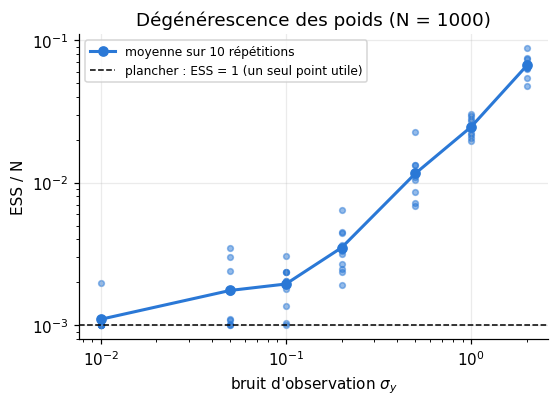

sigma_y = 2.0   : ESS/N moyen =   6.7 %
sigma_y = 1.0   : ESS/N moyen =   2.5 %
sigma_y = 0.5   : ESS/N moyen =   1.2 %
sigma_y = 0.2   : ESS/N moyen =   0.3 %
sigma_y = 0.1   : ESS/N moyen =   0.2 %
sigma_y = 0.05  : ESS/N moyen =   0.2 %
sigma_y = 0.01  : ESS/N moyen =   0.1 %


In [12]:
sigmas = [2.0, 1.0, 0.5, 0.2, 0.1, 0.05, 0.01]
N = 1_000
ess_rel = np.zeros((len(sigmas), R))
for a, s in enumerate(sigmas):
    for r in range(R):
        y_s = A @ x_star + s * rng.standard_normal(d_y)
        ess_rel[a, r] = importance_sampling(N, y_s, s)[1] / N

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for a, s in enumerate(sigmas):
    ax.scatter(np.full(R, s), ess_rel[a], s=14, color=BLEU, alpha=0.5)
ax.plot(sigmas, ess_rel.mean(axis=1), color=BLEU, lw=2, marker="o", label="moyenne sur 10 répétitions")
ax.axhline(1 / N, color="black", lw=1, ls="--", label="plancher : ESS = 1 (un seul point utile)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"bruit d'observation $\sigma_y$"); ax.set_ylabel("ESS / N")
ax.set_title(f"Dégénérescence des poids (N = {N})"); ax.legend(fontsize=8)
plt.show()
for s, e in zip(sigmas, ess_rel.mean(axis=1)):
    print(f"sigma_y = {s:<5} : ESS/N moyen = {100 * e:5.1f} %")

L'ESS relatif est déjà faible pour $\sigma_y = 1$ (quelques %), puis il s'effondre : dès $\sigma_y \approx 0{,}1$,
il touche presque le **plancher $\mathrm{ESS} = 1$**. Un seul tirage porte alors presque tout le poids, et
l'estimation repose sur un point. Et ici on n'est qu'en dimension 2 avec **une seule** observation.
En grande dimension (une image, c'est des milliers d'observations), la dégénérescence devient
**exponentielle** en la dimension (Bickel, Li & Bengtsson, 2008, cité par le papier) : l'IS naïf est inutilisable.

## 6. Bilan et suite

**Ce qu'on a fait :**
- un prior de diffusion « jouet » dont le débruiteur est exact, sans réseau de neurones ;
- le DDPM vu comme une **chaîne de Markov backward**, qui reproduit bien le prior ;
- un problème inverse dont on connaît le **vrai posterior** : c'est notre référence pour mesurer les erreurs ;
- la méthode la plus simple (IS = filtre bootstrap avec toute l'information à la fin) et sa limite :
  **les poids dégénèrent**.

**Idée clé pour la suite.** Plutôt que d'introduire $y$ d'un coup à la fin, on peut l'introduire **progressivement le
long de la chaîne backward**, avec des potentiels intermédiaires $g_k$ (éq. (2.4) du papier) :

$$
\pi_0(x_0) = \frac{1}{Z}\int g_n(x_n)\,p_n(x_n) \prod_{k=0}^{n-1} \frac{g_k(x_k)}{g_{k+1}(x_{k+1})}\, p_{k|k+1}(x_k \mid x_{k+1})\, \mathrm{d}x_{1:n}.
$$

Le produit « télescope » : la loi cible ne change pas, quel que soit le choix des $g_k$ (pourvu que $g_0$ soit la vraie
vraisemblance). C'est un **modèle de Feynman–Kac**, qu'on peut simuler avec un **filtre particulaire** :
c'est l'approche de MCGdiff (Cardoso et al., 2024), le papier précédent des mêmes auteurs.
DCPS, le papier qu'on étudie, part de la même écriture mais **évite les particules** pour passer à l'échelle
en grande dimension.

**Prochain notebook :** écrire ce modèle de Feynman–Kac et le simuler avec un filtre particulaire (paquet `particles`),
puis comparer à l'IS sur le même problème jouet.